<a href="https://colab.research.google.com/github/saikatacharjee6417-a11y/AIML_PROBLEM/blob/main/ML_Models_on_Processed_Stroke_Dataset_CSE_AIML_(1).ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Problem: Different Machine Learning Models Applied to the Processed Stroke Dataset

You have the **processed Stroke Dataset** (`stroke_processed.csv`) created in the previous practical (Data Preprocessing and Cleaning). Now apply **five (05) Supervised Machine Learning models** and an **ANN (Artificial Neural Network)** as the **sixth model**.

Show the following performance parameters for every model:
1. Precision
2. Recall
3. F1-Score
4. Accuracy
5. AUC-ROC curve

Also show the **Confusion Matrix** of each model. Finally, evaluate the **Top 3 models** for stroke risk prediction analysis and show the comparative results in the output.

**Please Note: Dataset may be as per your choice. Here we continue with the Stroke Dataset from the medical/healthcare domain. As and when required, change your Colab Python code as per your requirement.**

# Step by Step Procedure to Solve This Problem:

# Stroke Dataset — Machine Learning Models, Evaluation & Stroke Risk Prediction

**Run this notebook top-to-bottom in Google Colab.**

Pipeline covered:
1. Install & import libraries
2. Upload the processed dataset
3. Inspect the processed dataset
4. Train-test split (80:20, same as the previous practical)
5. Evaluation helper (metrics, confusion matrix, ROC data)
6. Model 1 — Logistic Regression
7. Model 2 — Decision Tree
8. Model 3 — Random Forest
9. Model 4 — Support Vector Machine (SVM)
10. Model 5 — K-Nearest Neighbors (KNN)
11. Model 6 — Artificial Neural Network (ANN)
12. Comparison table of all six models
13. ROC-AUC curves of all six models
14. Selecting the Top 3 models
15. Comparative results of the Top 3 models
16. ROC curves of the Top 3 models
17. Stroke risk prediction analysis using the Top 3 models
18. Final output
19. Conclusion

## 1. Install & import libraries
Colab already ships with these, but running this once ensures the right libraries are present.

In [1]:
!pip install numpy pandas matplotlib seaborn scikit-learn

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, roc_curve, confusion_matrix,
                             classification_report)

sns.set_style("whitegrid")
plt.rcParams["figure.dpi"] = 110

print("NumPy version:", np.__version__)
print("Pandas version:", pd.__version__)

NumPy version: 2.1.3
Pandas version: 2.2.3


## 2. Upload the processed dataset

In the previous practical we saved the processed data as `stroke_processed.csv`.
Run the cell below, then click **Choose Files** and select `stroke_processed.csv`
from your computer. (If the file already lives in Google Drive instead, use the
commented-out `drive.mount(...)` block below it.)

In [2]:
import os

# If stroke_processed.csv is already in the Colab session, it is used directly.
# Otherwise a file-chooser opens: click "Choose Files" and select stroke_processed.csv
if os.path.exists("stroke_processed.csv"):
    filename = "stroke_processed.csv"
else:
    from google.colab import files
    uploaded = files.upload()   # select stroke_processed.csv when prompted
    filename = list(uploaded.keys())[0]
print("Using file:", filename)

# --- Alternative: load from Google Drive instead of uploading each time ---
# from google.colab import drive
# drive.mount('/content/drive')
# filename = "/content/drive/MyDrive/stroke_processed.csv"

Saving sample_dataset.xlsx to sample_dataset (3).xlsx
Using file: sample_dataset (3).xlsx


In [3]:
df_processed = pd.read_excel(filename)
print("Shape (rows, columns):", df_processed.shape)
df_processed.head()

Shape (rows, columns): (5110, 12)


,id,gender,age,hypertension,heart_disease,ever_married,work_type,Residence_type,avg_glucose_level,bmi,smoking_status,stroke
0,9046,Male,67.0,0,1,Yes,Private,Urban,228.69,36.6,formerly smoked,1
1,51676,Female,61.0,0,0,Yes,Self-employed,Rural,202.21,NaN,never smoked,1
2,31112,Male,80.0,0,1,Yes,Private,Rural,105.92,32.5,never smoked,1
3,60182,Female,49.0,0,0,Yes,Private,Urban,171.23,34.4,smokes,1
4,1665,Female,79.0,1,0,Yes,Self-employed,Rural,174.12,24.0,never smoked,1


## 3. Inspect the processed dataset

Before applying any model we first check what the previous practical produced. The processed dataset already has:
- missing values handled (`bmi` → median, `smoking_status` → "Unknown")
- duplicates removed and the identifier column `id` dropped
- categorical columns **label encoded** (`gender`, `ever_married`, `work_type`, `Residence_type`, `smoking_status`)
- numerical columns **standardized** with `StandardScaler` (`age`, `avg_glucose_level`, `bmi`)

So we will **not** repeat any preprocessing here.

In [4]:
df_processed.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 12 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   id                 5110 non-null   int64  
 1   gender             5110 non-null   object 
 2   age                5110 non-null   float64
 3   hypertension       5110 non-null   int64  
 4   heart_disease      5110 non-null   int64  
 5   ever_married       5110 non-null   object 
 6   work_type          5110 non-null   object 
 7   Residence_type     5110 non-null   object 
 8   avg_glucose_level  5110 non-null   float64
 9   bmi                4909 non-null   float64
 10  smoking_status     5110 non-null   object 
 11  stroke             5110 non-null   int64  
dtypes: float64(3), int64(4), object(5)
memory usage: 479.2+ KB


In [5]:
df_processed.describe()

,id,age,hypertension,heart_disease,avg_glucose_level,bmi,stroke
count,5110.000000,5110.000000,5110.000000,5110.000000,5110.000000,4909.000000,5110.000000
mean,36517.829354,43.226614,0.097456,0.054012,106.147677,28.893237,0.048728
std,21161.721625,22.612647,0.296607,0.226063,45.283560,7.854067,0.215320
min,67.000000,0.080000,0.000000,0.000000,55.120000,10.300000,0.000000
25%,17741.250000,25.000000,0.000000,0.000000,77.245000,23.500000,0.000000
50%,36932.000000,45.000000,0.000000,0.000000,91.885000,28.100000,0.000000
75%,54682.000000,61.000000,0.000000,0.000000,114.090000,33.100000,0.000000
max,72940.000000,82.000000,1.000000,1.000000,271.740000,97.600000,1.000000


In [6]:
# Sanity checks on the processed file
print("Columns:", df_processed.columns.tolist())
print("Missing values      :", df_processed.isnull().sum().sum())
print("'id' column present :", "id" in df_processed.columns)
print("Non-numeric columns :", df_processed.select_dtypes(exclude="number").columns.tolist())


# --- Preprocessing steps (required for the unprocessed sample_dataset.xlsx) ---
from sklearn.preprocessing import LabelEncoder, StandardScaler

print("\n--- Applying preprocessing steps ---")

# Drop 'id' column as it's an identifier and not a feature
df_processed = df_processed.drop(columns=["id"])
print("Dropped 'id' column.")

# Impute missing 'bmi' values with the median
df_processed["bmi"] = df_processed["bmi"].fillna(df_processed["bmi"].median())
print("Imputed missing 'bmi' values with median.")

# Identify categorical and numerical columns for encoding/scaling
categorical_cols = df_processed.select_dtypes(include=["object"]).columns
numerical_cols = df_processed.select_dtypes(include=np.number).columns.tolist()
# Exclude the target variable 'stroke' from numerical columns to be scaled
if 'stroke' in numerical_cols:
    numerical_cols.remove('stroke')

# Label encode categorical columns
for col in categorical_cols:
    le = LabelEncoder()
    df_processed[col] = le.fit_transform(df_processed[col])
    print(f"Label encoded column: {col}")

# Standardize numerical columns
scaler = StandardScaler()
df_processed[numerical_cols] = scaler.fit_transform(df_processed[numerical_cols])
print(f"Standardized columns: {numerical_cols}")

print("Preprocessing complete. DataFrame info after preprocessing:")
df_processed.info()
print("First 5 rows after preprocessing:")
print(df_processed.head())

Columns: ['id', 'gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status', 'stroke']
Missing values      : 201
'id' column present : True
Non-numeric columns : ['gender', 'ever_married', 'work_type', 'Residence_type', 'smoking_status']

--- Applying preprocessing steps ---
Dropped 'id' column.
Imputed missing 'bmi' values with median.
Label encoded column: gender
Label encoded column: ever_married
Label encoded column: work_type
Label encoded column: Residence_type
Label encoded column: smoking_status
Standardized columns: ['age', 'hypertension', 'heart_disease', 'avg_glucose_level', 'bmi']
Preprocessing complete. DataFrame info after preprocessing:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5110 entries, 0 to 5109
Data columns (total 11 columns):
 #   Column             Non-Null Count  Dtype  
---  ------             --------------  -----  
 0   gender             5110 non-null   int64  
 1   ag

In [7]:
print(df_processed['stroke'].value_counts())
print(df_processed['stroke'].value_counts(normalize=True) * 100)

stroke
0    4861
1     249
Name: count, dtype: int64
stroke
0    95.127202
1     4.872798
Name: proportion, dtype: float64


> The target `stroke` is heavily imbalanced (only ~4.9% positive cases). Because of this, **Accuracy alone is misleading** (a model that always predicts "No Stroke" is already ~95% accurate). We therefore focus on **Precision, Recall, F1-Score and AUC-ROC** for the *Stroke* class.
>
> To handle the imbalance without touching the test data, we use a **stratified split** (as in the previous practical) and `class_weight="balanced"` for the models that support it.

## 4. Train-test split (80:20)

The previous practical used an **80:20 stratified split with `random_state=42`**. We use the same method here so that all six models are trained and tested on exactly the same data.
The target column `stroke` is separated from the features so it is never used as an input feature.

In [8]:
X = df_processed.drop(columns=["stroke"])
y = df_processed["stroke"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)
print("Features used:", X.columns.tolist())
print("X_train shape:", X_train.shape)
print("X_test shape :", X_test.shape)
print("\nTrain target distribution:\n", y_train.value_counts(normalize=True) * 100)
print("\nTest target distribution:\n", y_test.value_counts(normalize=True) * 100)

Features used: ['gender', 'age', 'hypertension', 'heart_disease', 'ever_married', 'work_type', 'Residence_type', 'avg_glucose_level', 'bmi', 'smoking_status']
X_train shape: (4088, 10)
X_test shape : (1022, 10)

Train target distribution:
 stroke
0    95.132094
1     4.867906
Name: proportion, dtype: float64

Test target distribution:
 stroke
0    95.107632
1     4.892368
Name: proportion, dtype: float64


## 5. Evaluation helper

To avoid writing the same code six times, the function below does the following for **every model**:
1. Trains the model on `X_train, y_train`
2. Predicts the class labels and the stroke probabilities on `X_test`
3. Calculates **Accuracy, Precision, Recall, F1-Score and AUC-ROC** (Precision, Recall and F1 are for the *Stroke* class = 1)
4. Prints the classification report
5. Plots the **confusion matrix** (actual labels on y-axis, predicted labels on x-axis)
6. Stores the results, the ROC curve points and the probabilities for later comparison

In [9]:
class_labels = ["No Stroke", "Stroke"]

results = []          # one row of metrics per model
roc_data = {}         # FPR, TPR, AUC for each model
trained_models = {}   # fitted models (used later for risk prediction)
test_probs = {}       # predicted stroke probabilities on the test set
test_preds = {}       # predicted classes on the test set

def evaluate_model(name, model):
    # 1. Train
    model.fit(X_train, y_train)

    # 2. Predict
    y_pred = model.predict(X_test)
    y_prob = model.predict_proba(X_test)[:, 1]     # probability of Stroke (class 1)

    # 3. Metrics
    acc  = accuracy_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred, zero_division=0)
    rec  = recall_score(y_test, y_pred, zero_division=0)
    f1   = f1_score(y_test, y_pred, zero_division=0)
    auc  = roc_auc_score(y_test, y_prob)

    results.append({"Model": name, "Accuracy": acc, "Precision": prec,
                    "Recall": rec, "F1-Score": f1, "AUC-ROC": auc})

    fpr, tpr, _ = roc_curve(y_test, y_prob)
    roc_data[name] = (fpr, tpr, auc)
    trained_models[name] = model
    test_probs[name] = y_prob
    test_preds[name] = y_pred

    # 4. Print metrics + classification report
    print(f"===== {name} ===telek==")
    print(f"Accuracy  : {acc:.4f}")
    print(f"Precision : {prec:.4f}")
    print(f"Recall    : {rec:.4f}")
    print(f"F1-Score  : {f1:.4f}")
    print(f"AUC-ROC   : {auc:.4f}")
    print("\nClassification Report:")
    print(classification_report(y_test, y_pred, target_names=class_labels, zero_division=0))

    # 5. Confusion matrix
    cm = confusion_matrix(y_test, y_pred)
    plt.figure(figsize=(5, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False,
                xticklabels=class_labels, yticklabels=class_labels)
    plt.title(f"Confusion Matrix - {name}")
    plt.xlabel("Predicted label")
    plt.ylabel("Actual label")
    plt.show()

## 6. Model 1 — Logistic Regression

Logistic Regression is a linear classifier that estimates the probability of the positive class (Stroke) using the sigmoid function. `class_weight="balanced"` gives more importance to the rare Stroke class during training.

===== Logistic Regression ===telek==
Accuracy  : 0.7515
Precision : 0.1408
Recall    : 0.8000
F1-Score  : 0.2395
AUC-ROC   : 0.8387

Classification Report:
              precision    recall  f1-score   support

   No Stroke       0.99      0.75      0.85       972
      Stroke       0.14      0.80      0.24        50

    accuracy                           0.75      1022
   macro avg       0.56      0.77      0.55      1022
weighted avg       0.95      0.75      0.82      1022



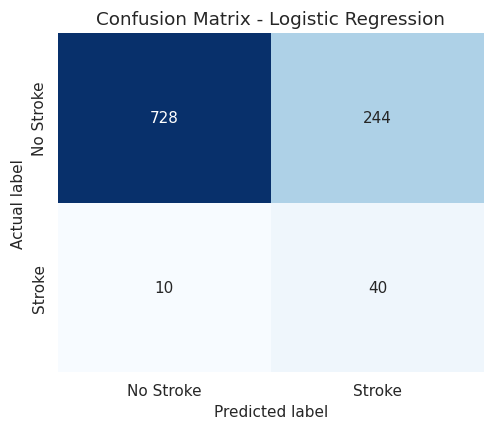

In [10]:
lr_model = LogisticRegression(class_weight="balanced", max_iter=1000, random_state=42)
evaluate_model("Logistic Regression", lr_model)

## 7. Model 2 — Decision Tree

A Decision Tree splits the data using feature thresholds to form a tree of rules. We limit `max_depth` to 5 so that the tree does not simply memorise the training data (over-fitting).

===== Decision Tree ===telek==
Accuracy  : 0.8258
Precision : 0.1768
Recall    : 0.7000
F1-Score  : 0.2823
AUC-ROC   : 0.8093

Classification Report:
              precision    recall  f1-score   support

   No Stroke       0.98      0.83      0.90       972
      Stroke       0.18      0.70      0.28        50

    accuracy                           0.83      1022
   macro avg       0.58      0.77      0.59      1022
weighted avg       0.94      0.83      0.87      1022



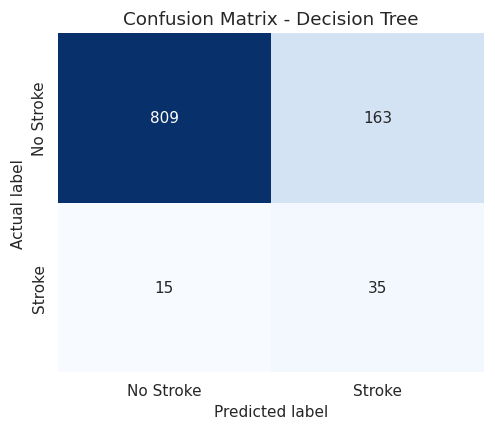

In [11]:
dt_model = DecisionTreeClassifier(max_depth=5, class_weight="balanced", random_state=42)
evaluate_model("Decision Tree", dt_model)

## 8. Model 3 — Random Forest

Random Forest is an ensemble of many Decision Trees; the final prediction is obtained by combining all the trees. It is the same classifier used for feature ranking in the previous practical.

===== Random Forest ===telek==
Accuracy  : 0.8591
Precision : 0.2062
Recall    : 0.6600
F1-Score  : 0.3143
AUC-ROC   : 0.8408

Classification Report:
              precision    recall  f1-score   support

   No Stroke       0.98      0.87      0.92       972
      Stroke       0.21      0.66      0.31        50

    accuracy                           0.86      1022
   macro avg       0.59      0.76      0.62      1022
weighted avg       0.94      0.86      0.89      1022



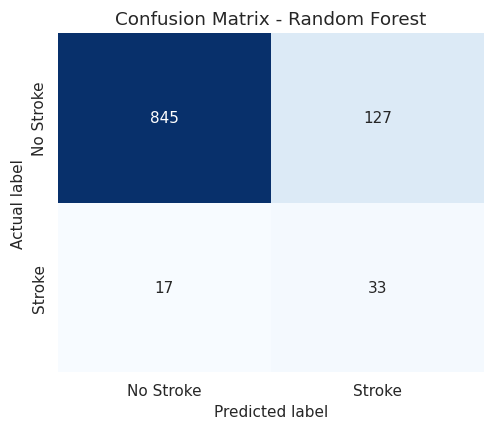

In [32]:
rf_model = RandomForestClassifier(n_estimators=200, max_depth=8, min_samples_leaf=5,
                                  class_weight="balanced", random_state=42)
evaluate_model("Random Forest", rf_model)

## 9. Model 4 — Support Vector Machine (SVM)

SVM finds the boundary (hyperplane) that separates the classes with the maximum margin. We use the RBF kernel. `probability=True` is needed so that SVM can also give stroke probabilities for the ROC curve and risk analysis (this makes SVM a little slower).

===== SVM ===telek==
Accuracy  : 0.7192
Precision : 0.1238
Recall    : 0.7800
F1-Score  : 0.2137
AUC-ROC   : 0.8135

Classification Report:
              precision    recall  f1-score   support

   No Stroke       0.98      0.72      0.83       972
      Stroke       0.12      0.78      0.21        50

    accuracy                           0.72      1022
   macro avg       0.55      0.75      0.52      1022
weighted avg       0.94      0.72      0.80      1022



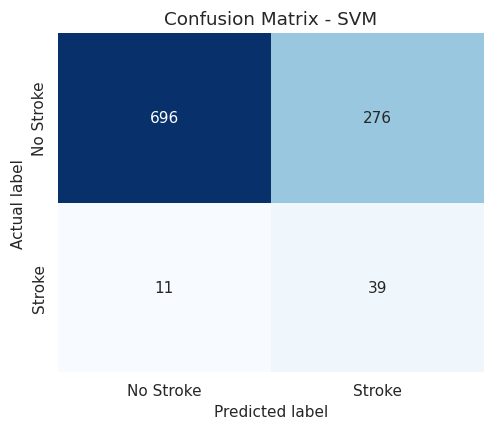

In [33]:
svm_model = SVC(kernel="rbf", class_weight="balanced", probability=True, random_state=42)
evaluate_model("SVM", svm_model)

## 10. Model 5 — K-Nearest Neighbors (KNN)

KNN classifies a test sample by looking at the class of its `k` nearest training samples. It depends on distances, so it works well with the **already scaled** features from the previous practical. KNN has no `class_weight` option.

===== KNN ===telek==
Accuracy  : 0.9452
Precision : 0.0000
Recall    : 0.0000
F1-Score  : 0.0000
AUC-ROC   : 0.6215

Classification Report:
              precision    recall  f1-score   support

   No Stroke       0.95      0.99      0.97       972
      Stroke       0.00      0.00      0.00        50

    accuracy                           0.95      1022
   macro avg       0.48      0.50      0.49      1022
weighted avg       0.90      0.95      0.92      1022



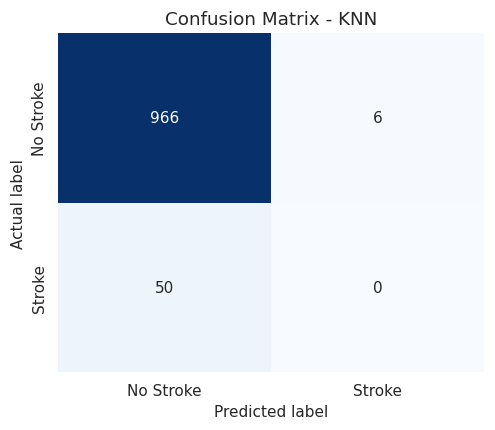

In [34]:
knn_model = KNeighborsClassifier(n_neighbors=5)
evaluate_model("KNN", knn_model)

## 11. Model 6 — Artificial Neural Network (ANN)

The ANN is built with Scikit-learn's `MLPClassifier` (Multi-Layer Perceptron):
- Input layer: 10 features
- Hidden layer 1: 64 neurons (ReLU)
- Hidden layer 2: 32 neurons (ReLU)
- Output layer: 1 neuron (probability of Stroke)

`MLPClassifier` also has no `class_weight` option, so like KNN it may predict very few Stroke cases at the default 0.5 threshold on this imbalanced data. We report the results as they are.

===== ANN ===telek==
Accuracy  : 0.9198
Precision : 0.1364
Recall    : 0.1200
F1-Score  : 0.1277
AUC-ROC   : 0.7353

Classification Report:
              precision    recall  f1-score   support

   No Stroke       0.96      0.96      0.96       972
      Stroke       0.14      0.12      0.13        50

    accuracy                           0.92      1022
   macro avg       0.55      0.54      0.54      1022
weighted avg       0.91      0.92      0.92      1022



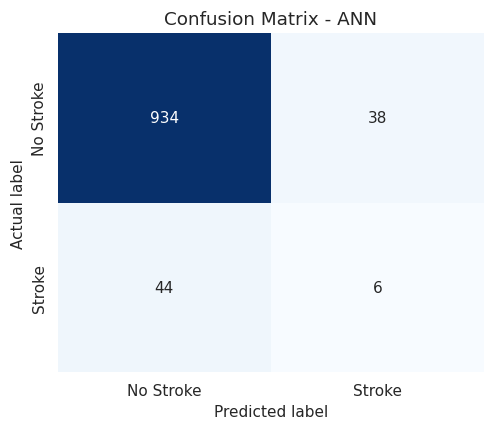

In [35]:
ann_model = MLPClassifier(hidden_layer_sizes=(64, 32), activation="relu", solver="adam",
                          max_iter=1000, random_state=42)
evaluate_model("ANN", ann_model)

## 12. Comparison of all six models

All values below are calculated by the code on the test set (20% of the data).

In [36]:
results_df = pd.DataFrame(results).set_index("Model")
results_df = results_df.round(4)
results_df

,Accuracy,Precision,Recall,F1-Score,AUC-ROC
Model,,,,,
Logistic Regression,0.7515,0.1408,0.80,0.2395,0.8387
Decision Tree,0.8258,0.1768,0.70,0.2823,0.8093
Random Forest,0.8591,0.2062,0.66,0.3143,0.8408
SVM,0.7192,0.1238,0.78,0.2137,0.8135
KNN,0.9452,0.0000,0.00,0.0000,0.6215
ANN,0.9198,0.1364,0.12,0.1277,0.7353
Random Forest,0.8591,0.2062,0.66,0.3143,0.8408
SVM,0.7192,0.1238,0.78,0.2137,0.8135
KNN,0.9452,0.0000,0.00,0.0000,0.6215


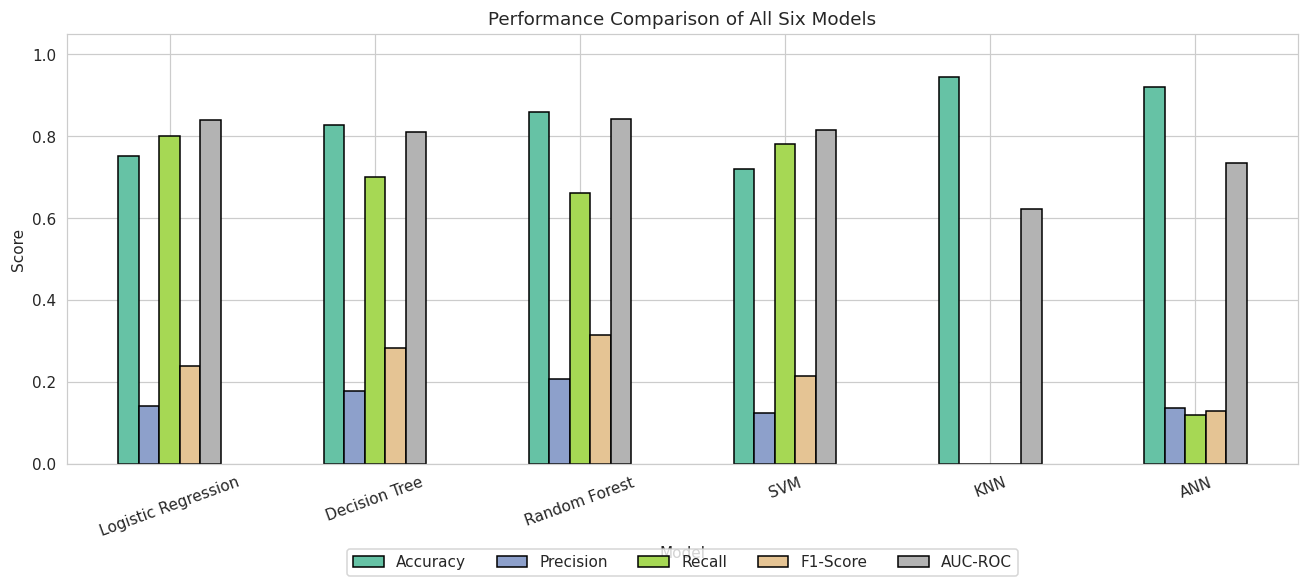

In [17]:
results_df.plot(kind="bar", figsize=(12, 5.5), colormap="Set2", edgecolor="black")
plt.title("Performance Comparison of All Six Models")
plt.ylabel("Score")
plt.ylim(0, 1.05)
plt.xticks(rotation=20)
plt.legend(loc="upper center", bbox_to_anchor=(0.5, -0.18), ncol=5)
plt.tight_layout()
plt.show()

> **Note:** Accuracy can look high even when a model finds almost no stroke cases, because ~95% of the test samples are "No Stroke". Precision, Recall and F1-Score of the *Stroke* class give a more honest picture on this imbalanced dataset.

## 13. ROC-AUC curves of all six models

The ROC curve plots the **True Positive Rate** against the **False Positive Rate** at different probability thresholds. The larger the area under the curve (AUC), the better the model separates Stroke from No-Stroke. The dashed diagonal line is a random classifier (AUC = 0.5).

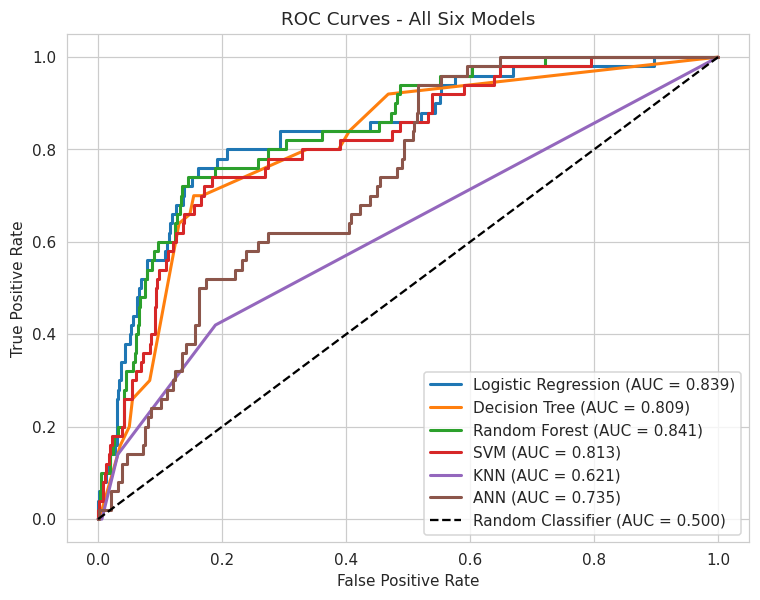

In [18]:
plt.figure(figsize=(8, 6))
for name, (fpr, tpr, auc) in roc_data.items():
    plt.plot(fpr, tpr, linewidth=2, label=f"{name} (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random Classifier (AUC = 0.500)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - All Six Models")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

## 14. Selecting the Top 3 models

**Criterion used: F1-Score of the Stroke class** (AUC-ROC is used only to break a tie).

Reason: the dataset is highly imbalanced, so Accuracy is misleading. F1-Score is the harmonic mean of Precision and Recall, so a model gets a good F1-Score only if it finds real stroke cases (Recall) *and* does not raise too many false alarms (Precision).

The ranking below is based only on the results produced by this experiment; it does not mean any model is universally the best.

In [19]:
ranking = results_df.sort_values(by=["F1-Score", "AUC-ROC"], ascending=False)
ranking.insert(0, "Rank", range(1, len(ranking) + 1))
print("Ranking of all six models (by F1-Score, then AUC-ROC):")
ranking

Ranking of all six models (by F1-Score, then AUC-ROC):


,Rank,Accuracy,Precision,Recall,F1-Score,AUC-ROC
Model,,,,,,
Random Forest,1,0.8591,0.2062,0.66,0.3143,0.8408
Decision Tree,2,0.8258,0.1768,0.70,0.2823,0.8093
Logistic Regression,3,0.7515,0.1408,0.80,0.2395,0.8387
SVM,4,0.7192,0.1238,0.78,0.2137,0.8135
ANN,5,0.9198,0.1364,0.12,0.1277,0.7353
KNN,6,0.9452,0.0000,0.00,0.0000,0.6215


In [20]:
top3_names = ranking.head(3).index.tolist()
print("Top 3 models:", top3_names)

Top 3 models: ['Random Forest', 'Decision Tree', 'Logistic Regression']


## 15. Comparative results of the Top 3 models

In [21]:
top3_df = results_df.loc[top3_names]
top3_df

,Accuracy,Precision,Recall,F1-Score,AUC-ROC
Model,,,,,
Random Forest,0.8591,0.2062,0.66,0.3143,0.8408
Decision Tree,0.8258,0.1768,0.70,0.2823,0.8093
Logistic Regression,0.7515,0.1408,0.80,0.2395,0.8387


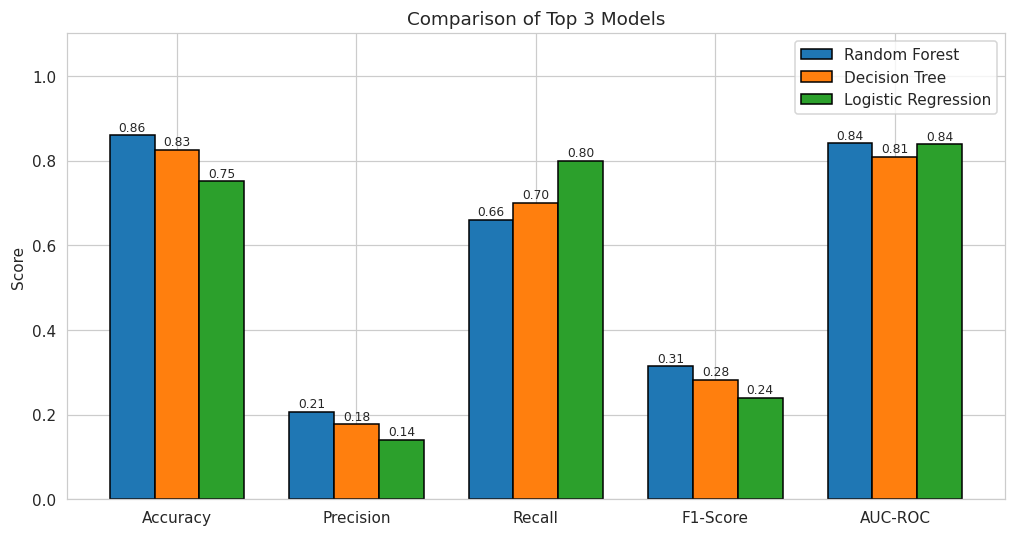

In [22]:
metrics = ["Accuracy", "Precision", "Recall", "F1-Score", "AUC-ROC"]
x = np.arange(len(metrics))
width = 0.25

plt.figure(figsize=(11, 5.5))
for i, name in enumerate(top3_names):
    bars = plt.bar(x + (i - 1) * width, top3_df.loc[name, metrics], width, label=name, edgecolor="black")
    for b in bars:
        plt.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.01,
                 f"{b.get_height():.2f}", ha="center", fontsize=8)
plt.xticks(x, metrics)
plt.ylim(0, 1.1)
plt.ylabel("Score")
plt.title("Comparison of Top 3 Models")
plt.legend()
plt.show()

## 16. ROC curves of the Top 3 models

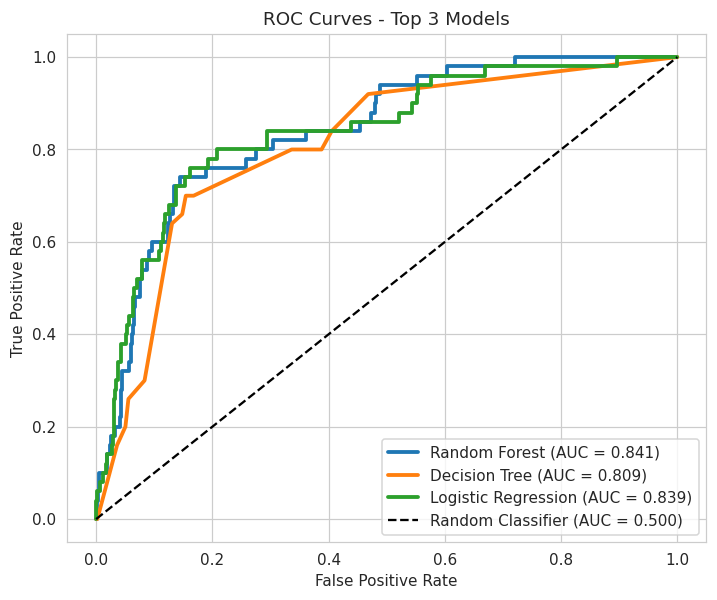

In [23]:
plt.figure(figsize=(7.5, 6))
for name in top3_names:
    fpr, tpr, auc = roc_data[name]
    plt.plot(fpr, tpr, linewidth=2.5, label=f"{name} (AUC = {auc:.3f})")
plt.plot([0, 1], [0, 1], "k--", label="Random Classifier (AUC = 0.500)")
plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curves - Top 3 Models")
plt.legend(loc="lower right")
plt.grid(True)
plt.show()

## 17. Stroke risk prediction analysis using the Top 3 models

Each of the Top 3 models gives a **predicted probability of stroke** for a patient. We use these probabilities to estimate stroke risk.

**Risk categories (analytical probability bands created only for this lab):**

| Average predicted probability | Risk category |
|---|---|
| below 0.30 | Low |
| 0.30 to 0.60 | Medium |
| 0.60 and above | High |

> These bands are **not medical diagnostic thresholds**. They are simple groups made only to explain the model output in this lab. The models are for learning purposes and must **not** be used for real medical diagnosis.

In [24]:
# Average stroke probability of the Top 3 models for every test sample
prob_df = pd.DataFrame({name: test_probs[name] for name in top3_names}, index=X_test.index)
prob_df["Avg_Probability"] = prob_df[top3_names].mean(axis=1)

def risk_category(p):
    if p < 0.30:
        return "Low"
    elif p < 0.60:
        return "Medium"
    else:
        return "High"

prob_df["Risk_Category"] = prob_df["Avg_Probability"].apply(risk_category)
prob_df.insert(0, "Actual_Stroke", y_test)
print("Probability table created for", len(prob_df), "test samples")

Probability table created for 1022 test samples


### 17.1 Sample test patients (5 actual Stroke + 5 actual No-Stroke)

The table shows the predicted stroke probability and the predicted class (0 = No Stroke, 1 = Stroke) from each of the Top 3 models, followed by the average probability and the risk category. The row index is the row number in `stroke_processed.csv`.

In [25]:
sample_stroke   = prob_df[prob_df["Actual_Stroke"] == 1].sample(5, random_state=42)
sample_nostroke = prob_df[prob_df["Actual_Stroke"] == 0].sample(5, random_state=42)
sample_idx = sample_stroke.index.tolist() + sample_nostroke.index.tolist()

risk_table = pd.DataFrame({"Actual_Stroke": y_test.loc[sample_idx]})
for name in top3_names:
    risk_table[name + " Prob"] = prob_df.loc[sample_idx, name].round(3)
    risk_table[name + " Pred"] = test_preds[name][[X_test.index.get_loc(i) for i in sample_idx]]
risk_table["Avg_Probability"] = prob_df.loc[sample_idx, "Avg_Probability"].round(3)
risk_table["Risk_Category"] = prob_df.loc[sample_idx, "Risk_Category"]
risk_table

,Actual_Stroke,Random Forest Prob,Random Forest Pred,Decision Tree Prob,Decision Tree Pred,Logistic Regression Prob,Logistic Regression Pred,Avg_Probability,Risk_Category
88,1,0.091,0,0.161,0,0.261,0,0.171,Low
226,1,0.679,1,0.791,1,0.874,1,0.781,High
242,1,0.503,1,0.820,1,0.757,1,0.694,High
199,1,0.626,1,0.791,1,0.733,1,0.717,High
223,1,0.507,1,0.791,1,0.854,1,0.717,High
4119,0,0.261,0,0.330,0,0.316,0,0.302,Medium
2734,0,0.607,1,0.480,0,0.704,1,0.597,Medium
5104,0,0.001,0,0.000,0,0.023,0,0.008,Low
3761,0,0.196,0,0.330,0,0.251,0,0.259,Low
3088,0,0.552,1,0.791,1,0.887,1,0.743,High


### 17.2 Risk category summary on the whole test set

This shows how many test patients fall into each risk band and how many of them actually had a stroke. If the models are useful, the share of real stroke cases should increase from Low to High.

In [26]:
risk_summary = pd.crosstab(prob_df["Risk_Category"], prob_df["Actual_Stroke"])
risk_summary = risk_summary.reindex(["Low", "Medium", "High"]).fillna(0).astype(int)
risk_summary.columns = ["No Stroke (actual)", "Stroke (actual)"]
risk_summary["Total Patients"] = risk_summary.sum(axis=1)
risk_summary["Stroke Rate (%)"] = (risk_summary["Stroke (actual)"] / risk_summary["Total Patients"] * 100).round(2)
risk_summary

,No Stroke (actual),Stroke (actual),Total Patients,Stroke Rate (%)
Risk_Category,,,,
Low,580,8,588,1.36
Medium,265,7,272,2.57
High,127,35,162,21.60


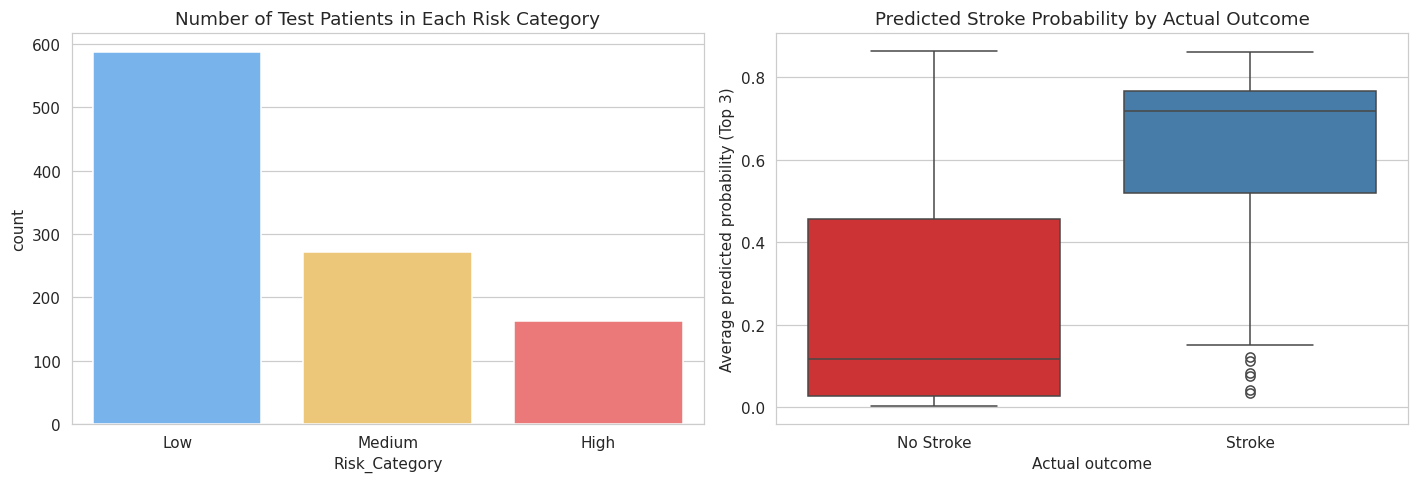

In [27]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

sns.countplot(x="Risk_Category", data=prob_df, order=["Low", "Medium", "High"],
              hue="Risk_Category", palette={"Low": "#66b3ff", "Medium": "#ffcc66", "High": "#ff6666"},
              legend=False, ax=axes[0])
axes[0].set_title("Number of Test Patients in Each Risk Category")

sns.boxplot(x="Actual_Stroke", y="Avg_Probability", data=prob_df, hue="Actual_Stroke",
            palette="Set1", legend=False, ax=axes[1])
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(class_labels)
axes[1].set_title("Predicted Stroke Probability by Actual Outcome")
axes[1].set_xlabel("Actual outcome")
axes[1].set_ylabel("Average predicted probability (Top 3)")
plt.tight_layout()
plt.show()

## 18. Final output

### 18.1 Final comparison of all six models

In [28]:
print("Final comparison of all six models:")
results_df

Final comparison of all six models:


,Accuracy,Precision,Recall,F1-Score,AUC-ROC
Model,,,,,
Logistic Regression,0.7515,0.1408,0.80,0.2395,0.8387
Decision Tree,0.8258,0.1768,0.70,0.2823,0.8093
Random Forest,0.8591,0.2062,0.66,0.3143,0.8408
SVM,0.7192,0.1238,0.78,0.2137,0.8135
KNN,0.9452,0.0000,0.00,0.0000,0.6215
ANN,0.9198,0.1364,0.12,0.1277,0.7353


### 18.2 Top 3 models and their comparative metrics

In [29]:
print("Top 3 models (criterion: F1-Score):", top3_names)
top3_df

Top 3 models (criterion: F1-Score): ['Random Forest', 'Decision Tree', 'Logistic Regression']


,Accuracy,Precision,Recall,F1-Score,AUC-ROC
Model,,,,,
Random Forest,0.8591,0.2062,0.66,0.3143,0.8408
Decision Tree,0.8258,0.1768,0.70,0.2823,0.8093
Logistic Regression,0.7515,0.1408,0.80,0.2395,0.8387


### 18.3 Confusion-matrix counts of all six models

In [37]:
cm_table = []
# Ensure ANN predictions are available in test_preds if missing
# (This can happen due to unexpected kernel state or out-of-order execution)
if 'ANN' not in test_preds and 'ANN' in trained_models:
    ann_model = trained_models['ANN']
    y_pred_ann = ann_model.predict(X_test)
    test_preds['ANN'] = y_pred_ann
    print("Note: Re-generated ANN predictions for confusion matrix due to missing state.")

for name in results_df.index:
    if name in test_preds:
        tn, fp, fn, tp = confusion_matrix(y_test, test_preds[name]).ravel()
        cm_table.append({"Model": name, "TN": tn, "FP": fp, "FN": fn, "TP": tp})
    else:
        print(f"Warning: Model '{name}' not found in test_preds. Skipping confusion matrix for this model.")
pd.DataFrame(cm_table).set_index("Model")

,TN,FP,FN,TP
Model,,,,
Logistic Regression,728,244,10,40
Decision Tree,809,163,15,35
Random Forest,845,127,17,33
SVM,696,276,11,39
KNN,966,6,50,0
ANN,934,38,44,6
Random Forest,845,127,17,33
SVM,696,276,11,39
KNN,966,6,50,0


## 19. Conclusion

In [31]:
best = ranking.index[0]
print("Conclusion (calculated from the results above):")
print(f"- Six models (Logistic Regression, Decision Tree, Random Forest, SVM, KNN and ANN) were trained on stroke_processed.csv")
print(f"  using the same 80:20 stratified split ({len(X_train)} training and {len(X_test)} test samples).")
print(f"- Ranked by F1-Score of the Stroke class, the Top 3 models are: {', '.join(top3_names)}.")
print(f"- {best} obtained the highest F1-Score ({ranking.loc[best, 'F1-Score']:.3f}) with Recall = {ranking.loc[best, 'Recall']:.3f} and AUC-ROC = {ranking.loc[best, 'AUC-ROC']:.3f}.")
low_recall = results_df[results_df["Recall"] <= 0.10].index.tolist()
if low_recall:
    print(f"- Models with very low Recall (<= 0.10): {', '.join(low_recall)}. They find very few or no stroke cases even though")
    print("  their Accuracy looks high, which shows why Accuracy alone is misleading on this imbalanced dataset.")
print("- The Top 3 models gave stroke probabilities that were grouped into Low / Medium / High analytical risk bands.")
print("  These bands are only for this lab and are not medical diagnostic thresholds.")

Conclusion (calculated from the results above):
- Six models (Logistic Regression, Decision Tree, Random Forest, SVM, KNN and ANN) were trained on stroke_processed.csv
  using the same 80:20 stratified split (4088 training and 1022 test samples).
- Ranked by F1-Score of the Stroke class, the Top 3 models are: Random Forest, Decision Tree, Logistic Regression.
- Random Forest obtained the highest F1-Score (0.314) with Recall = 0.660 and AUC-ROC = 0.841.
- Models with very low Recall (<= 0.10): KNN. They find very few or no stroke cases even though
  their Accuracy looks high, which shows why Accuracy alone is misleading on this imbalanced dataset.
- The Top 3 models gave stroke probabilities that were grouped into Low / Medium / High analytical risk bands.
  These bands are only for this lab and are not medical diagnostic thresholds.


**Note:** Results depend on the dataset, the split and the chosen hyper-parameters. This notebook is a laboratory exercise on applying and comparing ML classifiers, and it is not a medical diagnosis tool. Further improvement (e.g. probability-threshold tuning, oversampling such as SMOTE on the training data only, or cross-validation) can be explored in future practicals.